In [1]:
#  importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#  loading dataset
data=pd.read_csv("Crime Data.csv")

PRE-ANALYSI

In [3]:
#  shape of dataset
data.shape

(31, 10)

In [4]:
#  dataset info
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 10 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   YEAR                                  31 non-null     int64  
 1   TANZANIA POPULATION                   31 non-null     int64  
 2   UNEMPLOYMENT                          31 non-null     float64
 3   POPULATION DENSITY                    31 non-null     float64
 4   NET MIGRATION                         31 non-null     int64  
 5   GDP PER CAPITA                        31 non-null     float64
 6    Crimes Rate Against Humanity         31 non-null     float64
 7   Crimes Rate Against Societal Morals   31 non-null     float64
 8   Crimes Rate Against Property          31 non-null     float64
 9   CRIME_RATE                            31 non-null     float64
dtypes: float64(7), int64(3)
memory usage: 2.6 KB


In [5]:
#  first five rows
data.head()

,YEAR,TANZANIA POPULATION,UNEMPLOYMENT,POPULATION DENSITY,NET MIGRATION,GDP PER CAPITA,Crimes Rate Against Humanity,Crimes Rate Against Societal Morals,Crimes Rate Against Property,CRIME_RATE
0,1994,29442356,3.86,5.37,349348,228.89,0.77742,30.190,169.24,200.20762
1,1995,30383497,3.67,4.64,-109971,258.42,0.85052,29.525,211.62,241.99284
2,1996,30945762,3.48,3.33,-473007,313.66,1.01357,33.416,168.04,202.46843
3,1997,31578089,3.34,3.54,-13400,363.60,1.15142,30.427,251.09,282.67064
4,1998,32420458,3.28,4.19,-105184,386.38,1.19177,29.454,215.31,245.95380


In [6]:
#  last five rows
data.tail()

,YEAR,TANZANIA POPULATION,UNEMPLOYMENT,POPULATION DENSITY,NET MIGRATION,GDP PER CAPITA,Crimes Rate Against Humanity,Crimes Rate Against Societal Morals,Crimes Rate Against Property,CRIME_RATE
26,2020,60972798,1.79,4.50,-18587,1117.42,1.83265,24.153,40.94,66.92397
27,2021,62830412,1.88,4.45,-7704,1159.86,1.84601,30.410,33.77,66.02671
28,2022,64711821,1.57,4.32,-37557,1207.52,1.86600,32.819,33.64,68.32217
29,2023,66617606,1.57,4.76,-39388,1224.00,1.83736,6.944,9.10,17.87966
30,2024,68560157,1.56,4.81,-29865,1186.72,1.01725,19.686,73.95,94.65375


In [7]:
#  checking impossible values
for col in data.columns:
    if col=="NET MIGRATION":
        continue
    elif col=="TANZANIA POPULATION" or col=="":
        a=data[col]<=0
        if a.sum()>0:
            print(data.loc[a,col],col)
        else:pass
    else:
        a=data[col]<=0
        if a.sum()>0:
            print(data.loc[a,col],col)
        else:pass

            

In [8]:
#  Check duplicated values
data.duplicated().sum()

np.int64(0)

In [9]:
#  Chek missing values
data.isnull().sum()

YEAR                                    0
TANZANIA POPULATION                     0
UNEMPLOYMENT                            0
POPULATION DENSITY                      0
NET MIGRATION                           0
GDP PER CAPITA                          0
 Crimes Rate Against Humanity           0
Crimes Rate Against Societal Morals     0
Crimes Rate Against Property            0
CRIME_RATE                              0
dtype: int64

FIXING

In [10]:
# fixing incorrect format
data["YEAR"]=data["YEAR"].astype("str")

POST ANALYSIS

In [11]:
#  Descriptive statistic
data.describe()

,TANZANIA POPULATION,UNEMPLOYMENT,POPULATION DENSITY,NET MIGRATION,GDP PER CAPITA,Crimes Rate Against Humanity,Crimes Rate Against Societal Morals,Crimes Rate Against Property,CRIME_RATE
count,3.100000e+01,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000,31.000000
mean,4.564862e+07,2.690645,4.777419,-58438.225806,713.215161,1.460666,29.919355,126.390000,157.769727
std,1.186378e+07,0.720291,0.508344,144670.969034,326.562773,0.369047,6.014489,67.121205,68.366091
min,2.944236e+07,1.560000,3.330000,-473007.000000,228.890000,0.777420,6.944000,9.100000,17.879660
25%,3.565980e+07,1.905000,4.500000,-125932.500000,402.175000,1.161955,28.999000,74.785000,106.667265
50%,4.363398e+07,3.020000,4.810000,-55444.000000,693.820000,1.587890,30.451000,126.650000,153.197410
75%,5.473845e+07,3.220000,5.085000,-11550.500000,1004.710000,1.801105,33.013500,176.005000,210.596370
max,6.856016e+07,3.860000,5.500000,349348.000000,1224.000000,2.031220,41.283000,251.090000,282.670640


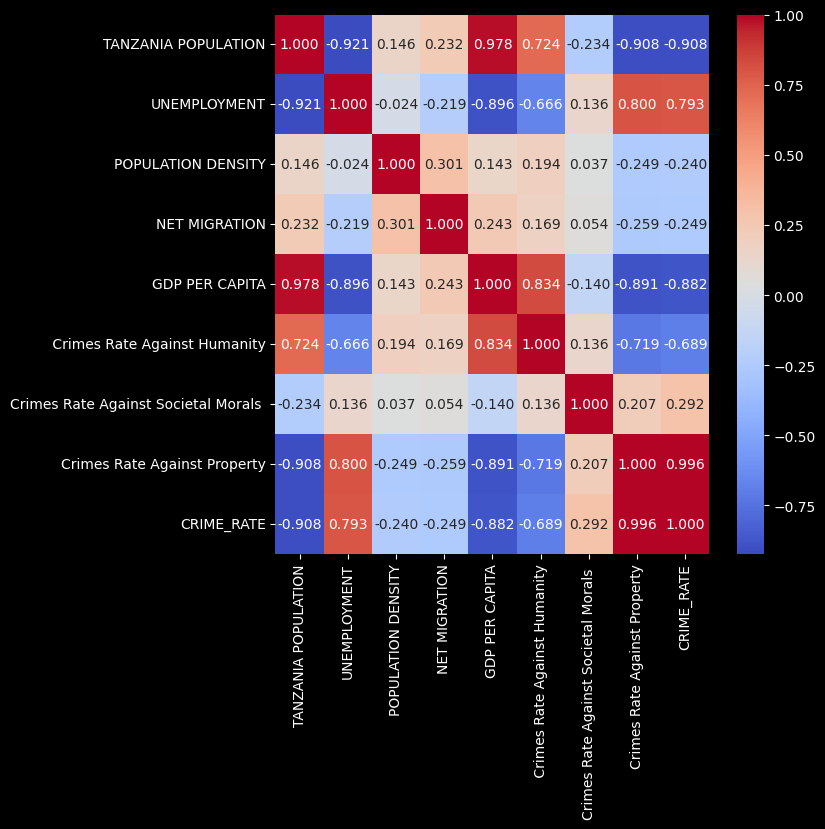

In [12]:
datanum=data.drop("YEAR",axis=1)
corr=datanum.corr()
plt.figure(figsize=(7,7))
sns.heatmap(
    corr,
    fmt=".3f",
    annot=True,
    cmap="coolwarm",
    linecolor="red"
)
plt.show()

In [13]:
# population analysis
# Generating one more column from existing population column
init=(data["TANZANIA POPULATION"].min())
limit=(data["TANZANIA POPULATION"].max())
interval=(limit-init)//3
bins=[]
for i in range(init-10,(limit*10),interval):
    if len(bins)<4:
        bins.append(i)
    else:break
bins[3]=bins[3]+10
data["Population Rank"]=pd.cut(
    data["TANZANIA POPULATION"],
    bins=bins,
    labels=["Low","Average","High"]
)

data.isnull().sum()
bins

[29442346, 42481613, 55520880, 68560157]

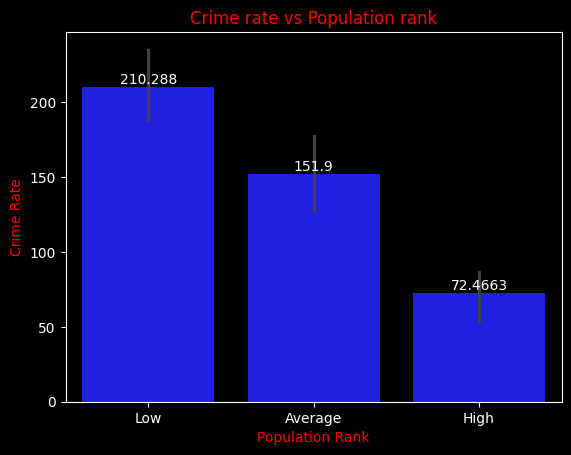

In [14]:
ax=sns.barplot(
    data=data,
    x="Population Rank",
    y="CRIME_RATE",
    color="b"
)
for label in ax.containers:
    ax.bar_label(label)
plt.title("Crime rate vs Population rank",color="r")
plt.ylabel("Crime Rate",color="r")
plt.xlabel("Population Rank",color="r")
plt.show()

RELATION BETWEEN CRIE RATE AND OTHER FACTORS

In [15]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype   
---  ------                                --------------  -----   
 0   YEAR                                  31 non-null     str     
 1   TANZANIA POPULATION                   31 non-null     int64   
 2   UNEMPLOYMENT                          31 non-null     float64 
 3   POPULATION DENSITY                    31 non-null     float64 
 4   NET MIGRATION                         31 non-null     int64   
 5   GDP PER CAPITA                        31 non-null     float64 
 6    Crimes Rate Against Humanity         31 non-null     float64 
 7   Crimes Rate Against Societal Morals   31 non-null     float64 
 8   Crimes Rate Against Property          31 non-null     float64 
 9   CRIME_RATE                            31 non-null     float64 
 10  Population Rank                       31 non-null     category
dtypes: category(1), flo

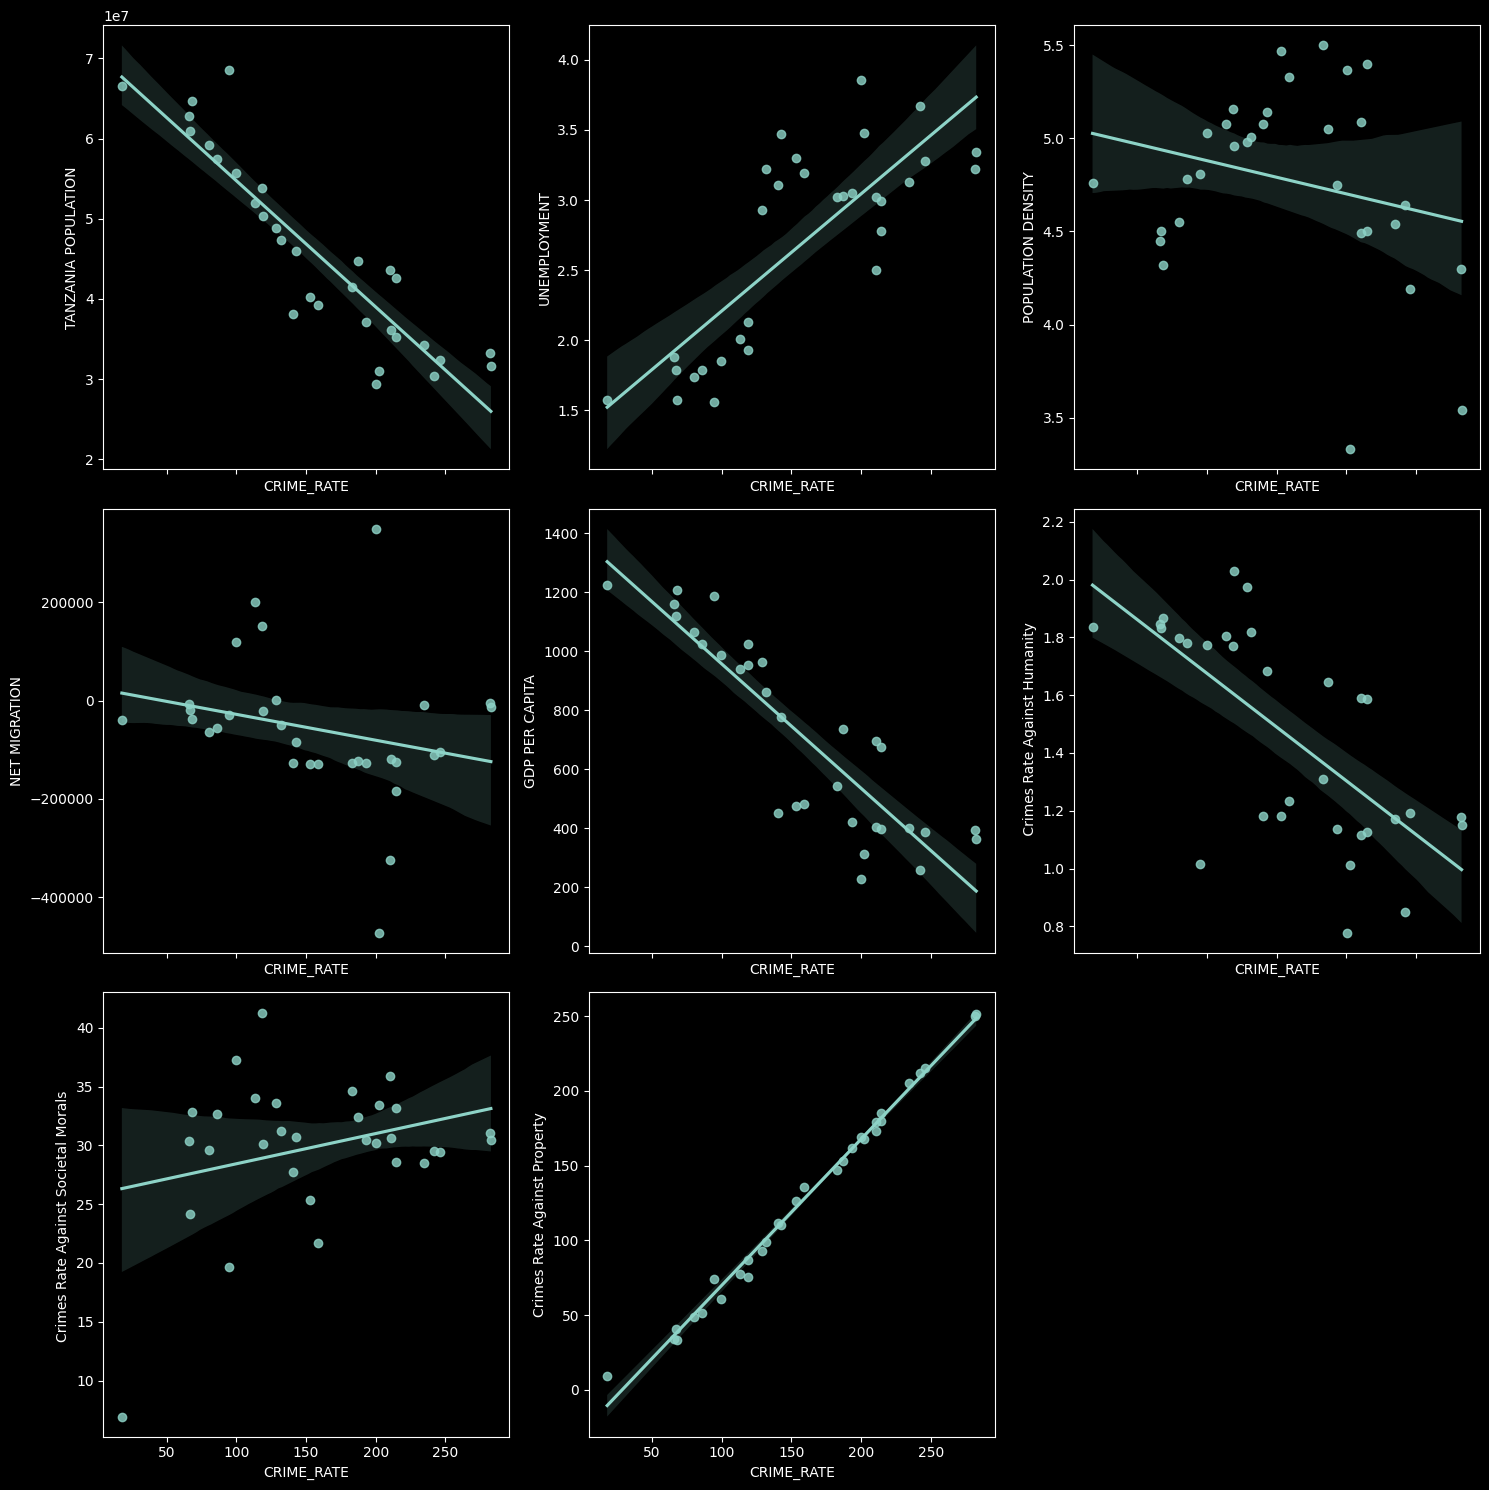

In [16]:
fig,ax=plt.subplots(3,3,sharex=True,figsize=(15,15)) # Create grid
ax=ax.flatten()
for i,col in enumerate(data.select_dtypes(include="number").columns):
    if i==8:continue
    sns.regplot(x=data["CRIME_RATE"],
    y=data[col],
    fit_reg=True,
    ax=ax[i]
    )
    
ax[8].axis("off")
plt.tight_layout()
plt.show()



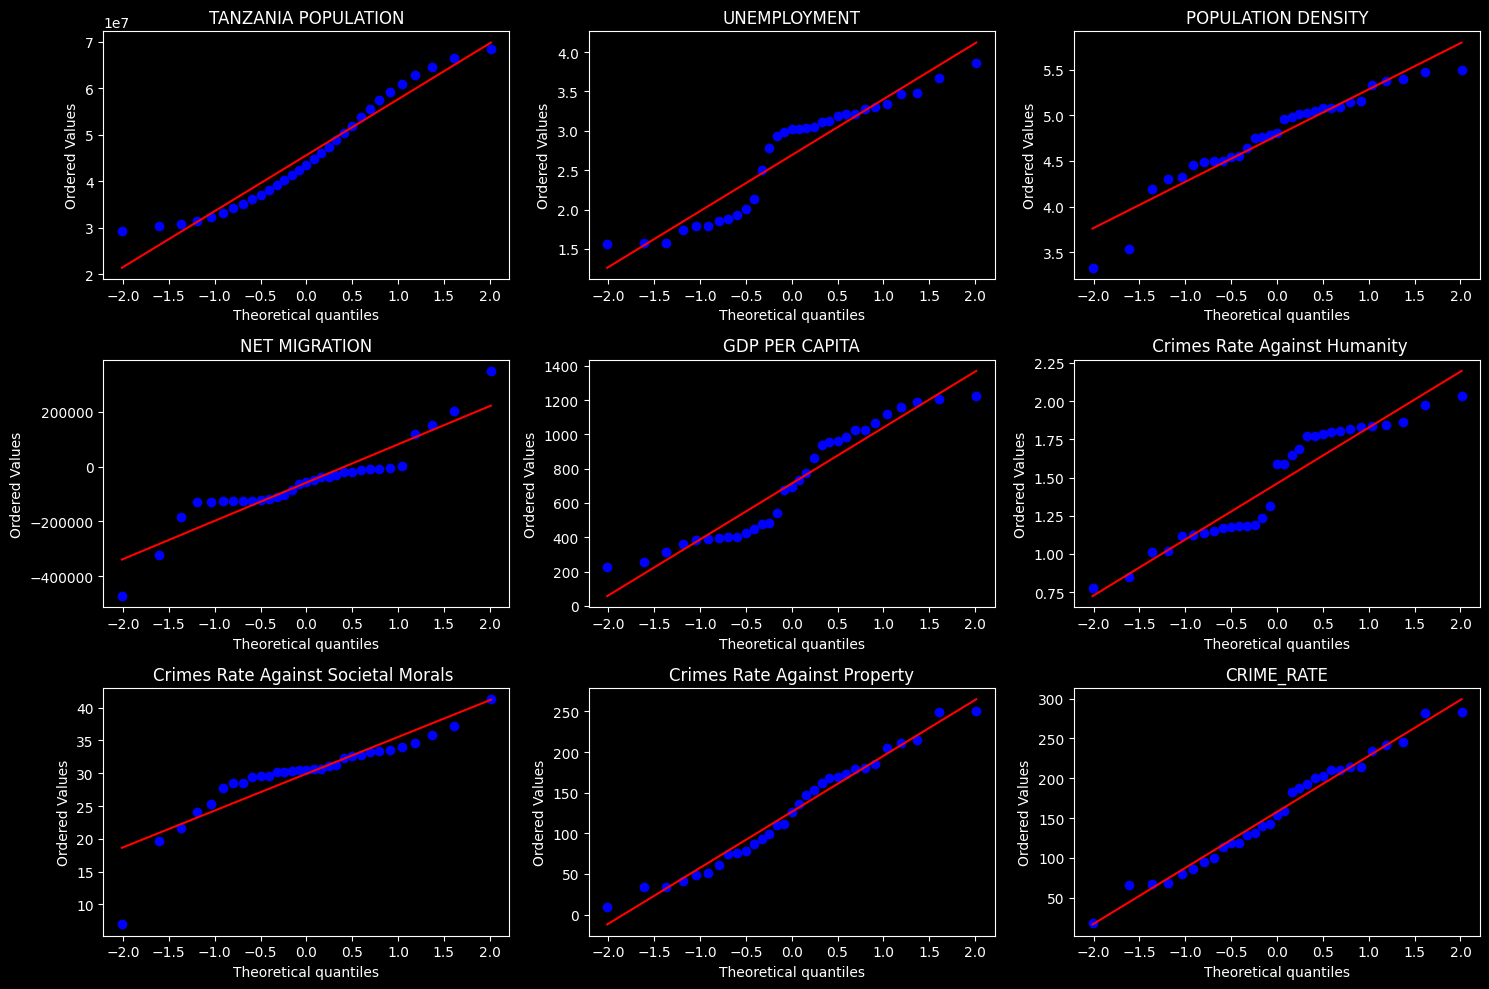

In [17]:
#  DISTRIBUTION OF VARIABLES
# Check if data are normally distributed
import scipy.stats as stats
fig,ax=plt.subplots(3,3,figsize=(15,10))
ax=ax.flatten()
for i,col in enumerate(data.select_dtypes(include="number").columns):
    stats.probplot(data[col],
               dist="norm",
               plot=ax[i]
    )
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

INFERENTIAL STATISTIC

In [18]:
data.columns

Index(['YEAR', 'TANZANIA POPULATION', 'UNEMPLOYMENT', 'POPULATION DENSITY',
       'NET MIGRATION', 'GDP PER CAPITA', ' Crimes Rate Against Humanity',
       'Crimes Rate Against Societal Morals ', 'Crimes Rate Against Property',
       'CRIME_RATE', 'Population Rank'],
      dtype='str')

In [19]:
# Testing whether population has effect on crime rate
#  t critical=1.96
data["Population Rank"].value_counts()

Population Rank
Low        14
Average     9
High        8
Name: count, dtype: int64

In [20]:
data.groupby("Population Rank")["CRIME_RATE"].mean()

Population Rank
Low        210.287857
Average    151.900139
High        72.466285
Name: CRIME_RATE, dtype: float64

In [21]:
data.groupby("Population Rank")["CRIME_RATE"].std()

Population Rank
Low        44.062274
Average    40.759119
High       25.495918
Name: CRIME_RATE, dtype: float64

t_calculated=9.29 while critical t is 2.086 hence reject null hypothesis and threrefore population affect crime rate

USING ONE WAY ANOVA

In [22]:
# Creating table of population factor with 3 variables
Population_Dict={
    "Low":[],
    "Average":[],
    "High":[]
}
for i,ind_value in enumerate(data["Population Rank"]):
    for j,de_value in enumerate(data["CRIME_RATE"]):
        if i==j:
            if ind_value=="Low":
                Population_Dict["Low"].append(de_value)
            elif ind_value=="Average":
                Population_Dict["Average"].append(de_value)
            else:
                Population_Dict["High"].append(de_value)

In [23]:
data["Population Rank"].value_counts()

Population Rank
Low        14
Average     9
High        8
Name: count, dtype: int64

In [24]:
# To balance number of elements in each array assign NaN to b
len(Population_Dict["Low"])
for key in Population_Dict:
    if key=="Low":continue
    for i in range(len(Population_Dict[key]),len(Population_Dict["Low"])):
        Population_Dict[key].append(np.nan)

In [25]:
# convert to dataframe
Pop_Table=pd.DataFrame(Population_Dict)
Pop_Table

,Low,Average,High
0,200.20762,214.65683,99.81274
1,241.99284,210.53963,85.95850
2,202.46843,187.14334,80.15278
3,282.67064,142.90527,66.92397
4,245.95380,131.76136,66.02671
5,282.00580,128.72131,68.32217
6,234.59828,119.18162,17.87966
7,214.58605,113.52179,94.65375
8,210.65311,118.67010,NaN
9,193.39996,NaN,NaN


In [26]:
#Number of values in each group
Pop_Table.count()

Low        14
Average     9
High        8
dtype: int64

In [27]:
Pop_Table.mean()

Low        210.287857
Average    151.900139
High        72.466285
dtype: float64

In [28]:
# Mean value of the group
G1=Pop_Table.sum().sum()/31
print(round(G1,4))

157.7697


In [29]:
# Squared sum between group
Squared_values=[]
for i,mean in enumerate(Pop_Table.mean()):
    for j,n in enumerate(Pop_Table.count()):
        if i==j:
           Squared_values.append(round(n*pow((mean-G1),2),4))

SSbtwn=(sum(Squared_values))/2  
SSbtwn  

np.float64(48568.8211)

In [30]:
#  Sum within groups
sum_list=[]
for i,col in enumerate(Pop_Table.columns):
    for j,ind_mean in enumerate(Pop_Table.mean()):
        if i==j:
            summ=0
            for value in Pop_Table[col].dropna():
                var=pow((value-ind_mean),2)
                summ=summ+var
            sum_list.append(summ)
SSwith=(max(sum_list))/28
SSwith

901.4032854565532

In [31]:
f=round(SSbtwn/SSwith,4)
f

np.float64(53.8813)

In [32]:
# calculated f value is greater than critical f value at dfbtn=2, dfwiyhn=28 and sl=5% which is 3.34
# There enough evidence to reject null hypothesis and therefore Population has effect on Crime rate

MODEL TRAINING

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,root_mean_squared_error
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
import joblib

In [34]:
# Separating feature and target
feature=data.drop(["YEAR","CRIME_RATE"],axis=1)
target=data["CRIME_RATE"]

In [35]:
# Separate numerical and categorical columns
numerical_cols=feature.select_dtypes(include="number").columns
categorical_cols=feature.select_dtypes(include="category").columns
categorical_cols

Index(['Population Rank'], dtype='str')

In [36]:
# Start numerical and categorical pipeline
numerical_pipeline=Pipeline([
    ("Impute",SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
])

In [37]:
# Start categorical pipeline
categorical_pipeline=Pipeline([
    ("Impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [38]:
# ombine numerical ad categorical transformer
preprocessor=ColumnTransformer([
    ("numer",numerical_pipeline,numerical_cols),
    ("cat",categorical_pipeline,categorical_cols)
    ])

In [39]:
# Start main pipeline
pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LinearRegression())
])

In [40]:
# 
#  isualize pipeline
from sklearn import set_config
set_config(display="diagram")
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers 

In [41]:
#  Split train and test data
x_train,x_test,y_train,y_test=train_test_split(
    feature,
    target,
    test_size=0.2,
    random_state=42
)

In [42]:
x_train.shape

(24, 9)

In [43]:
x_test.shape

(7, 9)

In [44]:
# Train model
pipeline.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numer', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers 

In [45]:
# Obtain training metrics
y_train_predict=pipeline.predict(x_train)
R2Score=r2_score(y_train,y_train_predict)
MSE=mean_squared_error(y_train,y_train_predict)
RMSE=root_mean_squared_error(y_train,y_train_predict)
print(f"""r2_score: {R2Score}
MSE: {MSE}
RME: {RMSE}""")


r2_score: 0.9999999992223069
MSE: 3.2627955846195097e-06
RME: 0.0018063210081875009


In [46]:
# Testing model
y_predict=pipeline.predict(x_test)
R2Score=r2_score(y_test,y_predict)
MSE=mean_squared_error(y_test,y_predict)
RMSE=root_mean_squared_error(y_test,y_predict)
print(f"""r2_score: {R2Score}
MSE: {MSE}
RME: {RMSE}""")

r2_score: 0.9999999962298534
MSE: 1.8642440860159877e-05
RME: 0.0043176892963898966


In [47]:
# save model
joblib.dump(pipeline,"Tools/Crime_Prediction_model.pkl")

['Tools/Crime_Prediction_model.pkl']